
Con SOLO_PRUEBA = False se habilitan el plan, la prueba de un recuadro y la descarga general.

Con SOLO_PRUEBA = True se omite la descarga general.


# instalar librerías

In [ ]:
%pip install -q eo-learn "sentinelhub>=3.11,<4" shapely matplotlib numpy pyproj huggingface_hub timm einops "setuptools<81"

# importo librerias

In [ ]:
import os
import re
import math
import glob
import datetime as dt
from dataclasses import dataclass
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import shape, box
from shapely.ops import unary_union
from pyproj import Transformer

from sentinelhub import (
    BBox, CRS, Geometry, SHConfig, DataCollection, SentinelHubCatalog,
    SentinelHubRequest, MimeType, MosaickingOrder, ResamplingType, get_utm_crs,
)
from sentinelhub.geo_utils import transform_point
from eolearn.core import EOPatch, EOTask, OverwritePermission

# Parámetros

Configura la zona de búsqueda (AOI), fechas, nubosidad máxima de la escena (0.3 = 30 %), resolución y bandas.
El AOI selecciona las escenas que lo tocan. Después se divide la extensión COMPLETA de esas escenas en recuadros,
incluidos los que quedan fuera del AOI. El porcentaje de nubes del catálogo se refiere al tile completo;
la máscara SCL comprueba los píxeles descargados.

La carpeta de salida termina en escenas_completas para no reutilizar los recuadros de la cuadrícula pequeña anterior,
porque sus números identificaban otras ubicaciones.

In [ ]:
CDSE_BASE_URL = "https://sh.dataspace.copernicus.eu"
CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

# Cordenadas de filtro/busqueda

AOI_GEOJSON = {
    "type": "Polygon",
    "coordinates": [[
        [-102.2362, 19.288836],
        [-102.2362, 19.619134],
        [-101.671895, 19.619134],
        [-101.671895, 19.288836],
        [-102.2362, 19.288836],
    ]],
}

TIME_INTERVAL = ("2026-03-01", "2026-03-31")   # rango de fechas
MAX_CLOUD = 0.3                                # 30 % de nubes
N_DATES = None                                 # None = todas las fechas; 2 = solo las 2 más despejadas
RESOLUTION = 10                                # metros por pixel
MAX_PX = 1500                                  # tamaño máx. de recuadro
DTYPE = np.float32                             # np.float16 = la mitad de espacio en disco
OUT_DIR = "/content/eopatches_s2_copernicus_escenas_completas"

# Nombres oficiales de las bandas de Sentinel-2 en Copernicus.
BANDS = ["B02", "B03", "B04", "B08"]
ALL_DOWNLOAD_BANDS = BANDS + ["B05", "B11", "B12", "B8A"]
SCL_VALID_CLASSES = [4, 5, 6]  # vegetación, suelo descubierto y agua
MIN_VALID = 0.5
# Ventana temporal corta por adquisición; no mezcla imágenes de días diferentes.
ACQUISITION_MARGIN_MIN = 10


SOLO_PRUEBA = True  # Omite la descarga masiva y los ejemplos históricos.

## Credenciales de Copernicus



In [ ]:
from getpass import getpass

def leer_credencial(nombre):
    valor = os.environ.get(nombre, "").strip()
    if not valor:
        try:
            from google.colab import userdata
            valor = (userdata.get(nombre) or "").strip()
        except ImportError:
            pass
        except Exception as error:
            if type(error).__name__ not in {"SecretNotFoundError", "NotebookAccessError"}:
                raise
    if not valor:
        valor = getpass(f"{nombre} (entrada oculta): ").strip()
    if not valor:
        raise ValueError(f"Falta {nombre}.")
    return valor

config = SHConfig()
config.sh_client_id = leer_credencial("CDSE_CLIENT_ID")
config.sh_client_secret = leer_credencial("CDSE_CLIENT_SECRET")
config.sh_base_url = CDSE_BASE_URL
config.sh_token_url = CDSE_TOKEN_URL
S2_CDSE = DataCollection.SENTINEL2_L2A.define_from(
    "S2_L2A_CDSE", service_url=CDSE_BASE_URL,
)
print("Configuración de Copernicus preparada. El acceso se comprueba al consultar el catálogo.")

Configuración de Copernicus preparada. El acceso se comprueba al consultar el catálogo.


Drive

Maestro Zucco no acrive esta celda es para guardar las imagenes en el drive.

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')
#OUT_DIR = '/content/drive/MyDrive/eopatches_s2'

# Funciones

- **Catálogo:** busca escenas Sentinel-2 L2A en Copernicus usando el AOI, las fechas y la nubosidad.
- **Recuadros:** divide la extensión completa de las escenas seleccionadas, como en el notebook original.
- **Descarga:** solicita cada recuadro UTM completo, sin limitarlo al AOI de búsqueda. Se conservan las bandas
  en reflectancia FLOAT32 y las máscaras SCL/dataMask. Las bandas se interpolan con bilinear;
  las clases SCL se solicitan aparte con vecino más cercano.
- **EOPatch, recortes opcionales y visualización:** conservan la organización del proyecto.

In [ ]:
# CATÁLOGO SENTINEL HUB DE COPERNICUS
@dataclass
class EscenaS2:
    id: str
    datetime: dt.datetime
    geometry: dict
    properties: dict

    @classmethod
    def desde_stac(cls, item):
        fecha = dt.datetime.fromisoformat(item["properties"]["datetime"].replace("Z", "+00:00"))
        props = dict(item["properties"])
        tile = re.search(r"_T(\d{2}[A-Z]{3})_", item["id"])
        props.setdefault("grid:code", tile.group(1) if tile else "?")
        return cls(item["id"], fecha, item["geometry"], props)


def get_catalog():
    return SentinelHubCatalog(config=config)


def aoi_bbox_wgs84(geojson=AOI_GEOJSON):
    return BBox(shape(geojson).bounds, crs=CRS.WGS84)


def search_items(catalog, bbox_wgs84, time_interval=TIME_INTERVAL, max_cloud=MAX_CLOUD):
    if not 0 <= max_cloud <= 1:
        raise ValueError("MAX_CLOUD debe estar entre 0 y 1.")
    consulta = catalog.search(
        S2_CDSE, bbox=bbox_wgs84, time=time_interval,
        filter=f"eo:cloud_cover < {max_cloud * 100:g}",
        filter_lang="cql2-text", limit=100,
    )
    # El iterador recorre automáticamente todas las páginas del catálogo.
    return [EscenaS2.desde_stac(item) for item in consulta]


def list_s2_scenes(catalog, bbox_wgs84, time_interval=TIME_INTERVAL, max_cloud=MAX_CLOUD):
    items = search_items(catalog, bbox_wgs84, time_interval, max_cloud)
    by_tile = defaultdict(list)
    for it in items:
        by_tile[it.properties.get("grid:code", "?")].append(it)
    print(f"Escenas Copernicus: {len(items)} | Tiles distintos: {len(by_tile)}")
    for tile, group in sorted(by_tile.items()):
        print(f"  Tile {tile} ({len(group)} escenas)")
        for it in sorted(group, key=lambda x: x.datetime):
            cc = it.properties.get("eo:cloud_cover", float("nan"))
            print(f"    {it.datetime:%Y-%m-%d} nubes: {cc:.1f}% {it.id}")
    return items


def select_dates(items, n_dates=None):
    #Se queda solo con las n fechas más despejadas
    if not n_dates:
        return items
    by_day = defaultdict(list)
    for it in items:
        by_day[it.datetime.date()].append(it)
    mean_cc = {d: float(np.mean([i.properties.get("eo:cloud_cover", 100) for i in g]))
               for d, g in by_day.items()}
    best = sorted(sorted(mean_cc, key=mean_cc.get)[:n_dates])
    print("\nFechas elegidas:", ", ".join(f"{d} ({mean_cc[d]:.1f}% nubes)" for d in best))
    return [i for d in best for i in by_day[d]]


# ----------------------------------------------------------------------------
# EXTENSIÓN COMPLETA DE LAS ESCENAS Y RECUADROS
# ----------------------------------------------------------------------------
def footprint_bbox_utm(items) -> BBox:
     # Calcula el rectángulo (en metros, UTM) que cubre todas las escenas encontradas.
    union = unary_union([shape(i.geometry) for i in items])
    wgs = BBox(union.bounds, crs=CRS.WGS84)
    utm = get_utm_crs(union.centroid.x, union.centroid.y)
    f = getattr(wgs, "transform_bounds", None)       # envolvente más exacta si existe
    return f(utm) if f else wgs.transform(utm)


def grid_bboxes(bbox: BBox, cols: int, rows: int):
    #Divide un BBox en cols x rows recuadros
    xs = np.linspace(bbox.min_x, bbox.max_x, cols + 1)
    ys = np.linspace(bbox.min_y, bbox.max_y, rows + 1)
    out = []
    for j in range(rows):
        for i in range(cols):
            out.append(BBox((xs[i], ys[j], xs[i + 1], ys[j + 1]), crs=bbox.crs))
    return out


def chunk_items(chunk: BBox, items):
    # Igual que en el original: el AOI filtra la búsqueda, no los recuadros de las escenas.
    poly = box(*tuple(chunk.transform(CRS.WGS84)))
    return [it for it in items if shape(it.geometry).intersects(poly)]


def plan_chunks(bbox_utm: BBox, items, resolution=RESOLUTION, max_px=MAX_PX, dtype=DTYPE):
   # divide la extensión total en recuadros de tamaño manejable y estima cuánto pesará la descarga.
    width_px = int((bbox_utm.max_x - bbox_utm.min_x) / resolution)
    height_px = int((bbox_utm.max_y - bbox_utm.min_y) / resolution)
    cols = math.ceil(width_px / max_px)
    rows = math.ceil(height_px / max_px)
    chunks = grid_bboxes(bbox_utm, cols, rows)
    con_datos = [i for i, c in enumerate(chunks) if chunk_items(c, items)]

    n_dates = len({it.datetime.date() for it in items})
    px_por_recuadro = (width_px / cols) * (height_px / rows)
    gb = len(con_datos) * px_por_recuadro * len(ALL_DOWNLOAD_BANDS) * np.dtype(dtype).itemsize * n_dates / 1e9

    print(f"\nExtensión completa de las escenas: {width_px} x {height_px} px a {resolution} m")
    print(f"Cuadrícula: {cols} x {rows} = {len(chunks)} recuadros "
          f"({len(con_datos)} con datos)")
    print(f"Fechas: {n_dates}  |  Peso estimado en disco: ~{gb:.1f} GB (sin comprimir)")
    return chunks


def first_chunk_with_data(chunks, items):
    #Índice del primer recuadro que sí tiene datos
    for i, c in enumerate(chunks):
        if chunk_items(c, items):
            return i
    raise ValueError("Ningún recuadro tiene datos")


def plot_plan(bbox_utm, chunks, items, aoi: BBox = None):
    #Escenas (azul), recuadros (rojo) y la zona de búsqueda AOI (verde)
    fig, ax = plt.subplots(figsize=(10, 7))
    for it in items:
        geom = shape(it.geometry)
        for g in getattr(geom, "geoms", [geom]):
            xs, ys = g.exterior.xy
            ax.fill(xs, ys, alpha=0.05, color="tab:blue")
    for i, c in enumerate(chunks):
        w = c.transform(CRS.WGS84)
        tiene = bool(chunk_items(c, items))
        ax.add_patch(plt.Rectangle((w.min_x, w.min_y), w.max_x - w.min_x, w.max_y - w.min_y,
                                   fill=False, edgecolor="red" if tiene else "lightgray",
                                   linewidth=1.2))
        ax.text((w.min_x + w.max_x) / 2, (w.min_y + w.max_y) / 2, str(i),
                ha="center", va="center", fontsize=8,
                color="red" if tiene else "lightgray")
    if aoi is not None:
        ax.add_patch(plt.Rectangle((aoi.min_x, aoi.min_y), aoi.max_x - aoi.min_x,
                                   aoi.max_y - aoi.min_y, fill=False,
                                   edgecolor="green", linewidth=2.5))
    a = bbox_utm.transform(CRS.WGS84)
    ax.set_xlim(a.min_x - 0.2, a.max_x + 0.2)
    ax.set_ylim(a.min_y - 0.2, a.max_y + 0.2)
    ax.set_aspect("equal")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.set_title("Escenas S2 completas (azul), recuadros (rojo) y AOI de búsqueda (verde)")
    plt.show()


# ----------------------------------------------------------------------------
# DESCARGA DE UN RECUADRO
# ----------------------------------------------------------------------------
def aoi_bbox_utm():
    centro = shape(AOI_GEOJSON).centroid
    crs = get_utm_crs(centro.x, centro.y)
    return aoi_bbox_wgs84().transform_bounds(crs)


def acquisition_interval(timestamp):
    if timestamp.tzinfo is None:
        timestamp = timestamp.replace(tzinfo=dt.timezone.utc)
    timestamp = timestamp.astimezone(dt.timezone.utc)
    margen = dt.timedelta(minutes=ACQUISITION_MARGIN_MIN)
    return tuple(t.isoformat().replace("+00:00", "Z")
                 for t in (timestamp - margen, timestamp + margen))


def aligned_grid_bbox(bbox, resolution):
    # Amplía menos de un píxel en el borde para mantener la resolución; no recorta al AOI.
    w = math.ceil((bbox.max_x - bbox.min_x) / resolution)
    h = math.ceil((bbox.max_y - bbox.min_y) / resolution)
    exact = BBox((bbox.min_x, bbox.max_y - h * resolution,
                  bbox.min_x + w * resolution, bbox.max_y), crs=bbox.crs)
    return exact, (w, h)


def make_evalscript(bands, quality=False):
    import json
    units = ["DN"] * len(bands) if quality else ["REFLECTANCE"] * len(bands)
    tipo = "UINT8" if quality else "FLOAT32"
    valores = ", ".join(f"s.{b}" for b in bands)
    return f"""//VERSION=3
function setup() {{
  return {{
    input: [{{bands: {json.dumps(bands)}, units: {json.dumps(units)}}}],
    output: {{bands: {len(bands)}, sampleType: "{tipo}"}},
    mosaicking: "SIMPLE"
  }};
}}
function evaluatePixel(s) {{ return [{valores}]; }}
"""


def build_cdse_request(bbox, size, timestamp, bands, quality=False):
    # Se descarga el recuadro completo. No se intersecta con AOI_GEOJSON.
    if max(size) > 2500:
        raise ValueError("Process API admite hasta 2500 píxeles por lado; reduce MAX_PX.")
    metodo = ResamplingType.NEAREST if quality else ResamplingType.BILINEAR
    return SentinelHubRequest(
        evalscript=make_evalscript(bands, quality=quality),
        input_data=[SentinelHubRequest.input_data(
            data_collection=S2_CDSE, time_interval=acquisition_interval(timestamp),
            maxcc=MAX_CLOUD, mosaicking_order=MosaickingOrder.LEAST_CC,
            upsampling=metodo, downsampling=metodo,
            other_args={"processing": {"harmonizeValues": True}},
        )],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=bbox, size=size, config=config,
    )


def download_cdse_array(bbox, size, timestamp, bands, quality=False):
    request = build_cdse_request(bbox, size, timestamp, bands, quality=quality)
    arr = np.asarray(request.get_data()[0])
    if arr.ndim == 2:
        arr = arr[..., None]
    expected = (size[1], size[0], len(bands))
    if arr.shape != expected:
        raise ValueError(f"Respuesta inesperada de Copernicus: {arr.shape}; se esperaba {expected}.")
    return arr


def download_acquisition(bbox, size, timestamp, bands):
    # SCL conserva sus etiquetas enteras: nunca se interpola con bilinear.
    quality = download_cdse_array(bbox, size, timestamp, ["SCL", "dataMask"], quality=True)
    valid = (quality[..., 1] > 0) & np.isin(quality[..., 0], SCL_VALID_CLASSES)
    if not valid.any():
        return None, valid
    reflectance = download_cdse_array(bbox, size, timestamp, bands).astype(np.float32)
    valid &= np.all(np.isfinite(reflectance), axis=-1)
    # Reflectancia cero puede ser válida; la ausencia de datos la determina dataMask.
    reflectance[~valid] = 0.0
    return reflectance, valid


def download_chunk(chunk, items, resolution=RESOLUTION, dtype=DTYPE):
    its = chunk_items(chunk, items)
    if not its:
        return None
    bb, size = aligned_grid_bbox(chunk, resolution)
    by_day = defaultdict(list)
    for it in its:
        by_day[it.datetime.date()].append(it)
    registros = []
    for dia, group in sorted(by_day.items()):
        # Una adquisición por día, priorizando la escena menos nublada.
        it = min(group, key=lambda x: x.properties.get("eo:cloud_cover", 100))
        data, valid = download_acquisition(bb, size, it.datetime, ALL_DOWNLOAD_BANDS)
        if data is not None and valid.any():
            registros.append((it.datetime.replace(tzinfo=None), data, valid))
    if not registros:
        return None
    times, arrays, masks = zip(*registros)
    data = np.stack(arrays).astype(dtype)
    eop = EOPatch(bbox=bb, timestamps=list(times))
    eop.data["BANDS"] = data[..., :4]
    eop.data["EXTRA"] = data[..., 4:7]
    eop.data["NIR_NARROW"] = data[..., 7:8]
    eop.mask["dataMask"] = np.stack(masks)[..., None]
    return eop


def download_all(chunks, items, out_dir=None, overwrite=False, only=None, **kwargs):
    # Descarga los recuadros que tienen datos y omite los ya guardados
    out_dir = out_dir or OUT_DIR
    os.makedirs(out_dir, exist_ok=True)
    for i, chunk in enumerate(chunks):
        if only is not None and i not in only:
            continue
        if not chunk_items(chunk, items):
            continue                                   # recuadro sin escenas
        path = os.path.join(out_dir, f"recuadro_{i}")
        if os.path.exists(path) and not overwrite:
            print(f"Recuadro {i} ya existe, se omite")
            continue
        print(f"Descargando recuadro {i}/{len(chunks) - 1} ...")
        eop = download_chunk(chunk, items, **kwargs)
        if eop is not None:
            eop.save(path, overwrite_permission=OverwritePermission.OVERWRITE_FEATURES)
    print("Listo.")

# Carga desde disco un recuadro ya descargado y lo devuelve como EOPatch.
def load_chunk(i, out_dir=None) -> EOPatch:
    out_dir = out_dir or OUT_DIR
    return EOPatch.load(os.path.join(out_dir, f"recuadro_{i}"))


# ----------------------------------------------------------------------------
# RECORTE FINO DENTRO DE UN RECUADRO
# ----------------------------------------------------------------------------
class CropToBBox(EOTask):
    #Recorta un EOPatch  a un sub-BBox en la misma CRS

    def __init__(self, sub_bbox: BBox):
        self.sub_bbox = sub_bbox

    def execute(self, eopatch: EOPatch) -> EOPatch:
        big, sub = eopatch.bbox, self.sub_bbox
        _, h, w, _ = next(iter(eopatch.data.values())).shape
        x_res = (big.max_x - big.min_x) / w
        y_res = (big.max_y - big.min_y) / h

        c0 = max(int(np.floor((sub.min_x - big.min_x) / x_res)), 0)
        c1 = min(int(np.ceil((sub.max_x - big.min_x) / x_res)), w)
        r0 = max(int(np.floor((big.max_y - sub.max_y) / y_res)), 0)
        r1 = min(int(np.ceil((big.max_y - sub.min_y) / y_res)), h)

        new = EOPatch(bbox=sub, timestamps=eopatch.timestamps)
        for name, arr in eopatch.data.items():
            new.data[name] = arr[:, r0:r1, c0:c1, :]
        for name, arr in eopatch.mask.items():
            new.mask[name] = arr[:, r0:r1, c0:c1, :]
        return new


def crop_custom_bbox(eopatch: EOPatch, coords) -> EOPatch:
    sub = BBox(coords, crs=CRS.WGS84).transform(eopatch.bbox.crs)
    return CropToBBox(sub).execute(eopatch)


def find_chunk_for_point(chunks, lon, lat):
    for i, c in enumerate(chunks):
        x, y = transform_point((lon, lat), CRS.WGS84, c.crs)
        if c.min_x <= x <= c.max_x and c.min_y <= y <= c.max_y:
            return i
    raise ValueError("El punto está fuera del área")


def split_patch(eopatch: EOPatch, grid=(4, 4)):
    sub_bboxes = grid_bboxes(eopatch.bbox, grid[0], grid[1])
    return [(b, CropToBBox(b).execute(eopatch)) for b in sub_bboxes]


# ----------------------------------------------------------------------------
# VISUALIZACIÓN
# ----------------------------------------------------------------------------
def rgb(eopatch: EOPatch, t=0, brightness=3.5):
  # Arma una imagen RGB (rojo, verde, azul) con brillo aumentado para poder verla.
    return np.clip(eopatch.data["BANDS"][t][..., [2, 1, 0]].astype(np.float32) * brightness, 0, 1)


def plot_patch(eopatch: EOPatch, t=0, title=""):
  # Muestra en pantalla la imagen RGB de un recuadro en una fecha dada.
    b = eopatch.bbox
    plt.figure(figsize=(8, 8))
    plt.imshow(rgb(eopatch, t), extent=(b.min_x, b.max_x, b.min_y, b.max_y))
    plt.title(title or f"{eopatch.timestamps[t]:%Y-%m-%d}")
    plt.xlabel("Este (m, UTM)")
    plt.ylabel("Norte (m, UTM)")
    plt.show()

# Contar recuadros descargados

In [ ]:
if not SOLO_PRUEBA and os.path.isdir(OUT_DIR):
    print(len(os.listdir(OUT_DIR)), "recuadros")

# Mosaico de todos los recuadros

In [ ]:
import glob

def ver_mosaico(fecha=None, paso=8, brillo=3.5, numeros=True, out_dir=None):
    #Muestra todos los recuadros descargados en un solo mapa.
    #fecha='2026-03-19' -> usa la fecha más cercana a esa en cada recuadro
    #paso=8  -> toma 1 de cada 8 pixeles (menor = más detalle, más RAM)
    out_dir = out_dir or OUT_DIR
    carpetas = sorted(glob.glob(os.path.join(out_dir, "recuadro_*")),
                      key=lambda p: int(p.split("_")[-1]))
    print(f"{len(carpetas)} recuadros encontrados")

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.set_facecolor("black")
    x0 = y0 = np.inf
    x1 = y1 = -np.inf

    for p in carpetas:
        i = int(p.split("_")[-1])
        eop = EOPatch.load(p)
        ts = eop.timestamps
        if fecha is None:
            t = 0
        else:
            objetivo = dt.datetime.fromisoformat(fecha)
            t = int(np.argmin([abs((x.replace(tzinfo=None) - objetivo).total_seconds())
                               for x in ts]))
        img = eop.data["BANDS"][t, ::paso, ::paso, :][..., [2, 1, 0]].astype(np.float32)
        img = np.clip(img * brillo, 0, 1)
        b = eop.bbox
        ax.imshow(img, extent=(b.min_x, b.max_x, b.min_y, b.max_y))
        if numeros:
            ax.text((b.min_x + b.max_x) / 2, (b.min_y + b.max_y) / 2, str(i),
                    color="yellow", ha="center", va="center", fontsize=9)
        x0, x1 = min(x0, b.min_x), max(x1, b.max_x)
        y0, y1 = min(y0, b.min_y), max(y1, b.max_y)
        del eop                                   # libera RAM

    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xlabel("Este (m, UTM)")
    ax.set_ylabel("Norte (m, UTM)")
    ax.set_title(f"Mosaico de {len(carpetas)} recuadros" + (f" - fecha ~{fecha}" if fecha else ""))
    plt.show()

if not SOLO_PRUEBA and glob.glob(os.path.join(OUT_DIR, "recuadro_*")):
    ver_mosaico()  # usa la primera fecha de cada recuadro
# ver_mosaico(fecha="2026-03-19")  #una fecha para que todos coincidan

# Funciones de bandas extra e índices

Define las funciones para agregar las bandas B05, B11 y B12 a cada recuadro, calcular los índices (NDVI, NDRE, NDMI, NBR) y graficarlos.

In [ ]:
from eolearn.core import FeatureType

# B05: borde rojo; B11: SWIR1; B12: SWIR2 (nativas de 20 m).
EXTRA_BANDS = ["B05", "B11", "B12"]
EXTRA_NAME = "EXTRA"


def add_extra_bands(i, chunk, items, out_dir=None, bands=EXTRA_BANDS, name=EXTRA_NAME,
                    overwrite=False, dtype=None):
    # Las descargas nuevas ya incluyen EXTRA y NIR_NARROW. Esta función permite actualizarlas.
    path = os.path.join(out_dir or OUT_DIR, f"recuadro_{i}")
    if not os.path.exists(path):
        return False
    eop = EOPatch.load(path)
    if name in eop.data and not overwrite:
        print(f"Recuadro {i}: ya tiene {name}, se omite")
        return False
    valid_old = eop.mask["dataMask"][..., 0].astype(bool)
    _, h, w = valid_old.shape
    arrays, masks = [], []
    for t, valid in zip(eop.timestamps, valid_old):
        data, new_valid = download_acquisition(eop.bbox, (w, h), t, bands)
        if data is None:
            data = np.zeros((h, w, len(bands)), dtype=np.float32)
        mask = valid & new_valid
        data[~mask] = 0.0
        arrays.append(data)
        masks.append(mask)
    eop.data[name] = np.stack(arrays).astype(dtype or DTYPE)
    eop.mask["dataMask"] = np.stack(masks)[..., None]
    eop.save(path, features=[(FeatureType.DATA, name), (FeatureType.MASK, "dataMask")],
             overwrite_permission=OverwritePermission.OVERWRITE_FEATURES)
    return True


def add_extra_all(chunks, items, only=None, **kwargs):
    n = 0
    for i, chunk in enumerate(chunks):
        if only is not None and i not in only:
            continue
        print(f"Recuadro {i}/{len(chunks) - 1} ...")
        if add_extra_bands(i, chunk, items, **kwargs):
            n += 1
    print(f"Listo. Recuadros actualizados: {n}")


def calc_indices(eop):
    B = eop.data["BANDS"].astype(np.float32)
    E = eop.data[EXTRA_NAME].astype(np.float32)
    red, nir = B[..., 2], B[..., 3]
    re1, sw1, sw2 = E[..., 0], E[..., 1], E[..., 2]
    m = eop.mask["dataMask"][..., 0]

    def nd(a, b):
        with np.errstate(divide="ignore", invalid="ignore"):
            r = (a - b) / (a + b)
        r = np.where(np.isfinite(r), r, np.nan)
        r[~m] = np.nan
        return r

    return {
        "NDVI": nd(nir, red),   # vigor / cobertura vegetal
        "NDRE": nd(nir, re1),   # clorofila del dosel (arboles frutales)
        "NDMI": nd(nir, sw1),   # humedad / estres hidrico
        "NBR":  nd(nir, sw2),   # suelo desnudo, quemas, cambio de uso
    }


def _estirar(a, lo=2, hi=98):
    v = a[np.isfinite(a) & (a != 0)]
    if v.size == 0:
        return np.zeros_like(a)
    p0, p1 = np.percentile(v, [lo, hi])
    return np.clip((a - p0) / (p1 - p0 + 1e-9), 0, 1)


def plot_extra(eop, t=0):
    B = eop.data["BANDS"][t].astype(np.float32)
    E = eop.data[EXTRA_NAME][t].astype(np.float32)
    bb = eop.bbox
    ext = (bb.min_x, bb.max_x, bb.min_y, bb.max_y)
    titulos = ["B05 borde rojo (clorofila)", "B11 SWIR1 (humedad)", "B12 SWIR2 (suelo/quemas)"]
    fig, axs = plt.subplots(1, 4, figsize=(22, 6))
    for k in range(3):
        axs[k].imshow(_estirar(E[..., k]), cmap="magma", extent=ext)
        axs[k].set_title(titulos[k])
    falso = np.dstack([_estirar(E[..., 1]), _estirar(B[..., 3]), _estirar(B[..., 0])])
    axs[3].imshow(falso, extent=ext)
    axs[3].set_title("Falso color agricultura (B11, B8, B2)")
    fig.suptitle(f"{eop.timestamps[t]:%Y-%m-%d}")
    plt.show()


def plot_indices(eop, t=0):
    ind = calc_indices(eop)
    bb = eop.bbox
    ext = (bb.min_x, bb.max_x, bb.min_y, bb.max_y)
    fig, axs = plt.subplots(1, 4, figsize=(22, 6))
    for ax, (nombre, arr) in zip(axs, ind.items()):
        a = arr[t]
        v = a[np.isfinite(a)]
        vmin, vmax = np.percentile(v, [2, 98]) if v.size else (-1, 1)
        im = ax.imshow(a, cmap="RdYlGn", vmin=vmin, vmax=vmax, extent=ext)
        ax.set_title(nombre)
        plt.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{eop.timestamps[t]:%Y-%m-%d}")
    plt.show()

# Buscar escenas, planear su extensión completa y estimar el tamaño

Se utiliza footprint_bbox_utm(items), como en la versión original.
El AOI verde solo selecciona las escenas. Los recuadros rojos cubren la extensión completa de esas escenas.

In [ ]:
if not SOLO_PRUEBA:
    catalog = get_catalog()
    aoi = aoi_bbox_wgs84()
    items = list_s2_scenes(catalog, aoi)
    items = select_dates(items, N_DATES)
    if not items:
        raise ValueError("No hay escenas. Amplía las fechas o ajusta MAX_CLOUD.")
    bbox_utm = footprint_bbox_utm(items)  # Extensión COMPLETA de las escenas, igual que antes.
    chunks = plan_chunks(bbox_utm, items)
    plot_plan(bbox_utm, chunks, items, aoi)

# Prueba
con un recuadro que tenga datos

In [ ]:
if not SOLO_PRUEBA:
    i0 = first_chunk_with_data(chunks, items)
    download_all(chunks, items, only=[i0], overwrite=True)

# Visualisacion de la prueba


In [ ]:
if not SOLO_PRUEBA:
    eop = load_chunk(i0)
    print(eop)
    print(eop.timestamps)
    plot_patch(eop, t=0, title=f'Recuadro {i0}')

# Descarga de todos los datos

La celda de prueba anterior descarga únicamente el primer recuadro con datos.
Esta celda recorre TODOS los recuadros del plan que intersectan las escenas seleccionadas.
Usa la carpeta nueva de escenas completas para no mezclar sus números con los del plan anterior de 12 recuadros.

In [ ]:
if not SOLO_PRUEBA:
    download_all(chunks, items)

# Recortes más pequeños de un recuadro


Muestra cómo cargar un recuadro y partirlo en celdas más pequeñas, quedándose con la de más cobertura válida.

In [ ]:
if not SOLO_PRUEBA:
    i = i0          # <- cambia por el recuadro que quieras ver (según el mosaico)
    t = 0           # índice de la fecha (0 = la primera)

    eop = load_chunk(i)
    print(eop.timestamps)

    # 1) El recuadro completo
    plot_patch(eop, t=t, title=f"Recuadro {i}")

    # 2) Dividirlo en celdas y mostrar la que tenga más datos válidos
    celdas = split_patch(eop, grid=(4, 4))
    validos = [c.mask["dataMask"][t].mean() for _, c in celdas]
    mejor = int(np.argmax(validos))
    print("Cobertura por celda:", np.round(validos, 2))
    plot_patch(celdas[mejor][1], t=t, title=f"Celda {mejor} (recuadro {i})")

# Espectros  (B05, B11, B12)



In [ ]:
if not SOLO_PRUEBA:
    i = i0          # <- recuadro a probar
    t = 0           # índice de la fecha (0 = la primera)

    add_extra_bands(i, chunks[i], items)

    eop = load_chunk(i)
    print(eop)                 # ahora debe tener DATA: BANDS y EXTRA
    plot_extra(eop, t=t)       # B05, B11, B12 y falso color de agricultura
    plot_indices(eop, t=t)     # NDVI, NDRE, NDMI y NBR

# Preparación de datos para Prithvi-EO 2.0 (600M-TL)

Modelo: [ibm-nasa-geospatial/Prithvi-EO-2.0-600M-TL](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-600M-TL).

| Prithvi espera | Datos de Copernicus | Preparación |
|---|---|---|
| Blue, Green, Red, NIR angosto, SWIR1, SWIR2 | B02, B03, B04, **B8A**, B11, B12 | Ordena esos seis canales; B08 y B05 quedan disponibles para tus índices |
| Escala 0–10000 y normalización por banda | Reflectancia `FLOAT32`, normalmente cercana a 0–1 | Multiplica una vez por 10000 y aplica media/desviación de la configuración oficial |
| Resolución de entrenamiento de 30 m (HLS) | Malla de 10 m; bandas de 20 m interpoladas | Promedia bloques de 3×3 usando píxeles válidos |
| Tiles de 224×224 | Ventana de 672×672 a 10 m | Genera un tile de 224×224 a 30 m |
| Cuatro fechas en esta prueba | Cuatro días útiles distintos | Ordena las fechas cronológicamente |
| Tiempo `[año, día del año]`, ubicación `[lat, lon]` | Fechas del catálogo y bbox UTM | Calcula los metadatos |
| Tensor `(B, C, T, H, W)` | EOPatch `(T, H, W, C)` | Construye `(1, 6, 4, 224, 224)` |

Se conserva la preparación original y la inferencia del modelo. Sentinel-2 sigue siendo una prueba de compatibilidad de entrada; cambiar la fuente de acceso no convierte las imágenes en HLS.

In [ ]:
import glob
import warnings
from dataclasses import dataclass

PRITHVI_REPO = "ibm-nasa-geospatial/Prithvi-EO-2.0-600M-TL"

# Orden OBLIGATORIO de canales
PRITHVI_BANDS = ["BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2"]
#B02,B03,B04,B8A,B11,B12

# Media y desviación por canal, en escala 0-10000 (valores del config.json de la familia Prithvi-EO-2.0).
PRITHVI_MEAN = np.array([1087.0, 1342.0, 1433.0, 2734.0, 1958.0, 1363.0], dtype=np.float32)
PRITHVI_STD = np.array([2248.0, 2179.0, 2178.0, 1850.0, 1242.0, 1049.0], dtype=np.float32)
PRITHVI_REFL_SCALE = 10000.0                # reflectancia 0-1 -> escala del modelo

PRITHVI_IMG_SIZE = 224                      # lado del tile (px)
PRITHVI_PATCH = 14                          # el lado debe ser múltiplo de esto
PRITHVI_NUM_FRAMES = 4                      # fechas por muestra
PRITHVI_RES = 30                            # m/px de entrenamiento (HLS)

# Metadatos
PRITHVI_DOY_OFFSET = 0                      # 1 de enero = 1
PRITHVI_LOCATION_ORDER = "lat_lon"          # orden de LocationEncoder

# B8A se solicita con su nombre oficial en Copernicus.
NIR_NARROW_ASSET = ["B8A"]
NIR_NARROW_NAME = "NIR_NARROW"              # nombre del feature dentro del EOPatch


PRITHVI_REV = "3d72adc6dfc4cc3862bf4f41da8c83db267193c9"

## Descarga de B8A y utilidades

In [ ]:
# DESCARGAR B8A (NIR ANGOSTO) Y GUARDARLA EN CADA EOPATCH
# Reutiliza add_extra_all(): misma malla exacta, mismas fechas, nuevo feature "NIR_NARROW".
def add_nir_narrow_all(chunks, items, only=None, **kwargs):
    add_extra_all(chunks, items, only=only, bands=NIR_NARROW_ASSET, name=NIR_NARROW_NAME, **kwargs)


def load_prithvi_config(repo_id=PRITHVI_REPO):
    """Lee config.json del repo oficial y devuelve bandas, media, desviación, tamaño y frames."""
    import json
    from huggingface_hub import hf_hub_download
    with open(hf_hub_download(repo_id=repo_id, filename="config.json", revision=PRITHVI_REV)) as f:
        cfg = json.load(f)["pretrained_cfg"]
    print("Bandas del config :", cfg["bands"])
    print("Media / desviación:", cfg["mean"], cfg["std"])
    print("img_size / frames :", cfg["img_size"], cfg["num_frames"])
    return cfg

In [ ]:
cfg = load_prithvi_config()
PRITHVI_MEAN = np.asarray(cfg["mean"], dtype=np.float32)
PRITHVI_STD = np.asarray(cfg["std"], dtype=np.float32)
assert (cfg["img_size"], cfg["num_frames"], cfg["patch_size"]) == (224, 4, [1, 14, 14])

config.json:   0%|          | 0.00/776 [00:00<?, ?B/s]

Bandas del config : ['B02', 'B03', 'B04', 'B05', 'B06', 'B07']
Media / desviación: [1087.0, 1342.0, 1433.0, 2734.0, 1958.0, 1363.0] [2248.0, 2179.0, 2178.0, 1850.0, 1242.0, 1049.0]
img_size / frames : 224 4


## De EOPatch a muestras de Prithvi

Bandas en orden, 30 m, escala/normalización, tiles de 224x224, selección de fechas y metadatos.

In [ ]:
@dataclass
class PrithviSample:
    x: np.ndarray                 # (6, T, 224, 224) float32, ya normalizado
    temporal_coords: np.ndarray   # (T, 2) float32  -> [año, día del año]
    location_coords: np.ndarray   # (2,)   float32  -> [lat, lon] del centro del tile
    valid: np.ndarray             # (T, 224, 224) bool, píxeles con dato real
    timestamps: list              # fechas usadas, en orden cronológico
    bbox: BBox                    # extensión UTM del tile (para volver a ubicar resultados)
    chunk_id: object = None       # recuadro de origen
    origin: tuple = (0, 0)        # (fila, col) del tile dentro del recuadro a 30 m


def build_prithvi_cube(eop, allow_b08_fallback=False):
    #Apila los 6 canales en el orden de Prithvi. Devuelve cubo (T,H,W,6) 0-1 y máscara (T,H,W)
    B = eop.data["BANDS"]                                   # blue, green, red, nir(B08)
    if EXTRA_NAME not in eop.data:
        raise KeyError(f"Falta '{EXTRA_NAME}' (B05/B11/B12). Corre add_extra_all() primero.")
    E = eop.data[EXTRA_NAME]                                # B05, B11, B12

    if NIR_NARROW_NAME in eop.data:
        nir = eop.data[NIR_NARROW_NAME][..., 0]             # B8A (el que pide Prithvi)
    else:
        raise KeyError(f"Falta '{NIR_NARROW_NAME}' (B8A). Corre add_nir_narrow_all() primero.")

    cube = np.stack([B[..., 0], B[..., 1], B[..., 2], nir, E[..., 1], E[..., 2]], axis=-1)
    cube = cube.astype(np.float32)
    valid = eop.mask["dataMask"][..., 0] & np.all(np.isfinite(cube), axis=-1)
    return cube, valid


def aggregate_to_resolution(cube, valid, bbox, src_res=RESOLUTION, dst_res=PRITHVI_RES, min_frac=0.5):
    #Baja de 10 m a 30 m promediando bloques (solo píxeles válidos). Ajusta el bbox al recorte
    f = int(round(dst_res / src_res))
    if f == 1:
        return cube, valid, bbox
    T, H, W, C = cube.shape
    H2, W2 = H // f, W // f                                  # se descarta el sobrante del borde
    c = cube[:, :H2 * f, :W2 * f].reshape(T, H2, f, W2, f, C)
    v = valid[:, :H2 * f, :W2 * f].reshape(T, H2, f, W2, f)
    w = v[..., None].astype(np.float32)
    n = w.sum(axis=(2, 4))
    out = np.where(v[..., None], c, 0).sum(axis=(2, 4)) / np.maximum(n, 1.0)
    valid_out = v.mean(axis=(2, 4)) >= min_frac
    out[~valid_out] = 0.0

    px_x = (bbox.max_x - bbox.min_x) / W                     # tamaño real de píxel original
    px_y = (bbox.max_y - bbox.min_y) / H
    new_bbox = BBox((bbox.min_x, bbox.max_y - H2 * f * px_y,
                     bbox.min_x + W2 * f * px_x, bbox.max_y), crs=bbox.crs)
    return out.astype(np.float32), valid_out, new_bbox


def tile_origins(n, size, stride):
    #Inicios de los tiles; el último se recorre hacia atrás para cubrir el borde sin relleno
    if n <= size:
        return [0]
    starts = list(range(0, n - size + 1, stride))
    if starts[-1] + size < n:
        starts.append(n - size)
    return starts


def select_frames(valid_tile, timestamps, n_frames, min_valid=0.5):
    #Elige las n_frames fechas con más cobertura válida (>= min_valid), en orden cronológico
    frac = valid_tile.mean(axis=(1, 2))
    ok = np.where(frac >= min_valid)[0]
    if len(ok) < n_frames:
        return None
    best = ok[np.argsort(-frac[ok])[:n_frames]]
    return sorted(best, key=lambda k: timestamps[k])


def normalize_for_prithvi(cube01, valid, mean=PRITHVI_MEAN, std=PRITHVI_STD):
    x = (cube01 * PRITHVI_REFL_SCALE - mean) / std
    x[~valid] = 0.0
    return x.astype(np.float32)


def make_temporal_coords(timestamps):
    #[año, día del año] por fecha (1 de enero = 1)
    return np.array([[t.year, t.timetuple().tm_yday + PRITHVI_DOY_OFFSET] for t in timestamps],
                    dtype=np.float32)


def make_location_coords(tile_bbox):
    # Centro del tile en WGS84, en el orden que defina PRITHVI_LOCATION_ORDER
    w = tile_bbox.transform(CRS.WGS84)
    lon, lat = (w.min_x + w.max_x) / 2, (w.min_y + w.max_y) / 2
    pair = [lon, lat] if PRITHVI_LOCATION_ORDER == "lon_lat" else [lat, lon]
    return np.array(pair, dtype=np.float32)


def eopatch_to_prithvi_samples(eop, chunk_id=None, n_frames=PRITHVI_NUM_FRAMES,
                               size=PRITHVI_IMG_SIZE, stride=None, min_valid=0.5,
                               allow_b08_fallback=False, verbose=True):
    #Un EOPatch -> lista de PrithviSample (tiles 224x224 a 30 m, n_frames fechas, con metadatos)."""
    stride = stride or size
    cube, valid = build_prithvi_cube(eop, allow_b08_fallback)
    cube, valid, bbox = aggregate_to_resolution(cube, valid, eop.bbox)
    ts = [t.replace(tzinfo=None) for t in eop.timestamps]

    # relleno si el recuadro es más chico que un tile (el relleno cuenta como sin dato)
    _, H, W, _ = cube.shape
    ph, pw = max(0, size - H), max(0, size - W)
    if ph or pw:
        cube = np.pad(cube, ((0, 0), (0, ph), (0, pw), (0, 0)))
        valid = np.pad(valid, ((0, 0), (0, ph), (0, pw)))
        H, W = H + ph, W + pw

    px = (bbox.max_x - bbox.min_x) / (W - pw)                # m por píxel a 30 m
    samples, skipped = [], 0
    for r0 in tile_origins(H, size, stride):
        for c0 in tile_origins(W, size, stride):
            v = valid[:, r0:r0 + size, c0:c0 + size]
            idx = select_frames(v, ts, n_frames, min_valid)
            if idx is None:
                skipped += 1
                continue
            x = normalize_for_prithvi(cube[idx, r0:r0 + size, c0:c0 + size], v[idx])
            x = np.ascontiguousarray(x.transpose(3, 0, 1, 2))        # (T,H,W,C) -> (C,T,H,W)
            max_y = bbox.max_y - r0 * px
            min_x = bbox.min_x + c0 * px
            tb = BBox((min_x, max_y - size * px, min_x + size * px, max_y), crs=bbox.crs)
            fechas = [ts[k] for k in idx]
            samples.append(PrithviSample(
                x=x, temporal_coords=make_temporal_coords(fechas),
                location_coords=make_location_coords(tb), valid=v[idx],
                timestamps=fechas, bbox=tb, chunk_id=chunk_id, origin=(r0, c0)))
    if verbose:
        print(f"Recuadro {chunk_id}: {len(samples)} tiles listos, {skipped} descartados "
              f"(menos de {n_frames} fechas con >= {min_valid:.0%} de cobertura)")
    return samples

## Una muestra real de la zona de interés desde Copernicus

Se usa **Sentinel-2 L2A** de CDSE. El catálogo busca escenas que cubren la ventana central de 6.72 km por lado. Process API devuelve solo ese recorte, en UTM a 10 m, con las ocho bandas del proyecto: B02, B03, B04, B08, B05, B11, B12 y B8A.

La máscara combina `dataMask` con SCL 4, 5 y 6 (vegetación, suelo descubierto y agua). Se buscan cuatro días diferentes con al menos 50 % de cobertura útil después de agregar a 30 m. El orden de los seis canales enviados al modelo es B02, B03, B04, B8A, B11 y B12.

Esta ventana central se usa únicamente para la prueba de Prithvi.
La descarga general de las secciones anteriores conserva la extensión completa de las escenas y todos sus recuadros.

In [ ]:
centro = shape(AOI_GEOJSON).centroid
crs_tile = get_utm_crs(centro.x, centro.y)
utm = Transformer.from_crs(4326, crs_tile.epsg, always_xy=True)
cx, cy = utm.transform(centro.x, centro.y)
lado = PRITHVI_IMG_SIZE * PRITHVI_RES
factor = PRITHVI_RES / RESOLUTION
if not float(factor).is_integer() or lado % RESOLUTION:
    raise ValueError("RESOLUTION debe dividir exactamente a 30 m y al lado de la ventana.")
x0 = round((cx - lado / 2) / RESOLUTION) * RESOLUTION
y1 = round((cy + lado / 2) / RESOLUTION) * RESOLUTION
bbox_tile = BBox((x0, y1 - lado, x0 + lado, y1), crs=crs_tile)
n_pix = int(lado / RESOLUTION)
ventana_wgs = box(*tuple(bbox_tile.transform_bounds(CRS.WGS84)))
if not shape(AOI_GEOJSON).covers(ventana_wgs):
    raise ValueError("La ventana debe quedar dentro del AOI. Ajusta su centro o amplía el AOI.")

catalog = get_catalog()
consulta = search_items(catalog, bbox_tile.transform_bounds(CRS.WGS84))
candidatas = sorted(
    (it for it in consulta if shape(it.geometry).covers(ventana_wgs)),
    key=lambda it: it.properties.get("eo:cloud_cover", 100),
)
print(len(candidatas), "escenas de Copernicus cubren la ventana y cumplen el filtro de nubes")
if not candidatas:
    raise ValueError("No hay escenas candidatas. Amplía TIME_INTERVAL o ajusta MAX_CLOUD.")

6 escenas de Copernicus cubren la ventana y cumplen el filtro de nubes


In [ ]:
def muestra_del_aoi():
    registros = []
    dias = set()
    f = int(PRITHVI_RES / RESOLUTION)
    for it in candidatas:
        dia = it.datetime.date()
        if dia in dias:
            continue
        bandas, util = download_acquisition(
            bbox_tile, (n_pix, n_pix), it.datetime, ALL_DOWNLOAD_BANDS,
        )
        if bandas is None:
            continue
        requeridas = bandas[..., [0, 1, 2, 7, 5, 6]]
        util &= np.all(np.isfinite(requeridas), axis=-1)
        cobertura30 = (util.reshape(PRITHVI_IMG_SIZE, f, PRITHVI_IMG_SIZE, f)
                       .mean(axis=(1, 3)) >= MIN_VALID).mean()
        if cobertura30 < MIN_VALID:
            continue
        registros.append((it.datetime.replace(tzinfo=None), bandas, util))
        dias.add(dia)
        print(it.id, f"cobertura útil a 30 m: {cobertura30:.1%}")
        if len(registros) == cfg["num_frames"]:
            break
    if len(registros) < cfg["num_frames"]:
        raise ValueError(f"Solo hay {len(registros)} fechas útiles. Amplía TIME_INTERVAL y repite la prueba.")
    registros.sort(key=lambda registro: registro[0])
    fechas, imagenes, mascaras = zip(*registros)
    datos = np.stack(imagenes)
    patch = EOPatch(bbox=bbox_tile, timestamps=list(fechas))
    patch.data["BANDS"] = datos[..., :4]
    patch.data[EXTRA_NAME] = datos[..., 4:7]
    patch.data[NIR_NARROW_NAME] = datos[..., 7:8]
    patch.mask["dataMask"] = np.stack(mascaras)[..., None]
    muestras = eopatch_to_prithvi_samples(patch, chunk_id="centro_AOI_Copernicus",
                                         min_valid=MIN_VALID)
    if len(muestras) != 1:
        raise ValueError("Se esperaba un único tile con cuatro fechas válidas.")
    return muestras[0]

muestra = muestra_del_aoi()
assert muestra.x.shape == (6, 4, 224, 224) and np.isfinite(muestra.x).all()
print("Fechas:", [t.date().isoformat() for t in muestra.timestamps])
print("Bandas:", PRITHVI_BANDS, "| Centro [lat, lon]:", muestra.location_coords)

S2A_MSIL2A_20260326T171721_N0512_R112_T13QHB_20260327T034455.SAFE cobertura útil a 30 m: 99.9%
S2B_MSIL2A_20260319T170919_N0512_R112_T13QHB_20260319T222051.SAFE cobertura útil a 30 m: 99.9%
S2C_MSIL2A_20260304T171211_N0512_R112_T13QHB_20260304T220715.SAFE cobertura útil a 30 m: 99.9%
S2B_MSIL2A_20260309T171039_N0512_R112_T13QHB_20260309T221621.SAFE cobertura útil a 30 m: 99.9%
Recuadro centro_AOI_Copernicus: 1 tiles listos, 0 descartados (menos de 4 fechas con >= 50% de cobertura)
Fechas: ['2026-03-04', '2026-03-09', '2026-03-19', '2026-03-26']
Bandas: ['BLUE', 'GREEN', 'RED', 'NIR_NARROW', 'SWIR_1', 'SWIR_2'] | Centro [lat, lon]: [  19.454021 -101.95406 ]


## Carga de los pesos oficiales e inferencia
Se usa la implementación del autoencoder publicada junto a los pesos de IBM y NASA, con la misma revisión para el código, la configuración y el checkpoint. El modelo oculta parte de los parches e intenta reconstruirlos. La prueba pasa si el modelo acepta los datos y devuelve valores finitos con la forma espacial esperada.

In [ ]:
import torch
import importlib.util
from huggingface_hub import hf_hub_download

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
x = torch.from_numpy(muestra.x).unsqueeze(0).to(device)
tiempo = torch.from_numpy(muestra.temporal_coords).unsqueeze(0).to(device)
lugar = torch.from_numpy(muestra.location_coords).unsqueeze(0).to(device)
assert x.shape == (1, 6, 4, 224, 224) and x.dtype == torch.float32
assert tiempo.shape == (1, 4, 2) and lugar.shape == (1, 2)
assert torch.isfinite(x).all() and torch.isfinite(lugar).all() and torch.isfinite(tiempo).all()
print("Entrada:", tuple(x.shape), "| Dispositivo:", device, "| Fechas TL:", tiempo.tolist())

def archivo_modelo(nombre):
    return hf_hub_download(PRITHVI_REPO, nombre, revision=PRITHVI_REV)

spec = importlib.util.spec_from_file_location("prithvi_mae", archivo_modelo("prithvi_mae.py"))
modulo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(modulo)
modelo = modulo.PrithviMAE(**cfg).to(device).eval()
pesos = torch.load(archivo_modelo("Prithvi_EO_V2_600M_TL.pt"), map_location="cpu",
                   weights_only=True, mmap=True)
# Igual que el ejemplo oficial, el modelo genera los embeddings posicionales fijos.
for clave in list(pesos):
    if "pos_embed" in clave:
        del pesos[clave]
faltan, sobran = modelo.load_state_dict(pesos, strict=False)
if any("pos_embed" not in k for k in faltan) or sobran:
    raise RuntimeError(f"Checkpoint incompatible. Faltan: {faltan}; sobran: {sobran}")
del pesos
print("Pesos preentrenados cargados.")

Entrada: (1, 6, 4, 224, 224) | Dispositivo: cuda | Fechas TL: [[[2026.0, 63.0], [2026.0, 68.0], [2026.0, 78.0], [2026.0, 85.0]]]


prithvi_mae.py:   0%|          | 0.00/30.0k [00:00<?, ?B/s]

Prithvi_EO_V2_600M_TL.pt: reconstructing file:   0%|          |  0.00B / 2.64GB            

Prithvi_EO_V2_600M_TL.pt: downloading bytes:           |  0.00B            

Pesos preentrenados cargados.


In [ ]:
torch.manual_seed(42)
with torch.inference_mode():
    perdida, tokens, mascara = modelo(x, temporal_coords=tiempo, location_coords=lugar,
                                      mask_ratio=cfg["mask_ratio"])
    reconstruccion = modelo.unpatchify(tokens)
assert reconstruccion.shape == x.shape
assert torch.isfinite(perdida).item() and torch.isfinite(reconstruccion).all().item()
print("PRUEBA SUPERADA")
print("Entrada:", tuple(x.shape), "| Reconstrucción:", tuple(reconstruccion.shape))
print("Pérdida de reconstrucción sobre parches ocultos:", round(perdida.item(), 4))

PRUEBA SUPERADA
Entrada: (1, 6, 4, 224, 224) | Reconstrucción: (1, 6, 4, 224, 224)
Pérdida de reconstrucción sobre parches ocultos: 0.0106


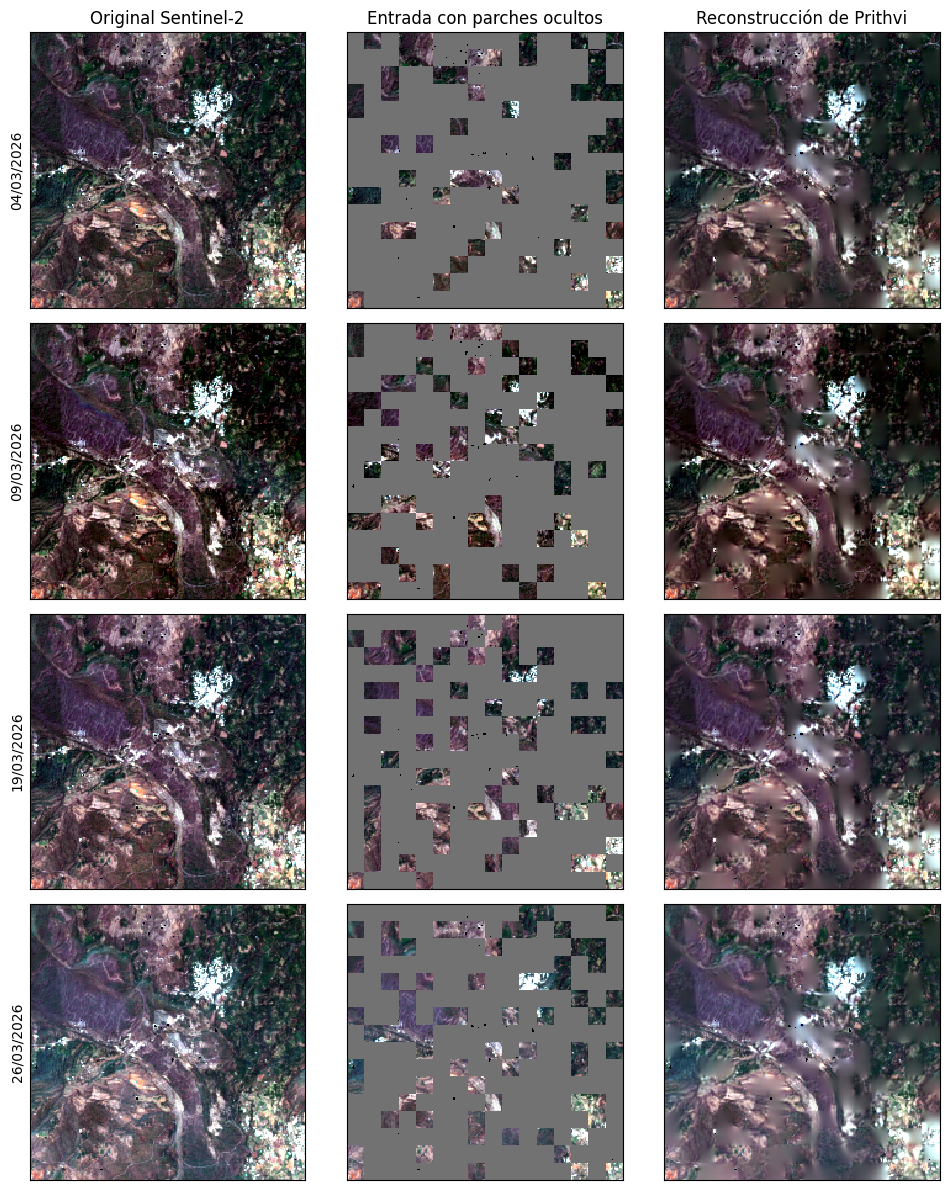

In [ ]:
# Mostrar las tres bandas visibles en orden rojo, verde y azul.
rgb_indices = [2, 1, 0]
def a_rgb(tensor):
    canales = tensor[0, rgb_indices].detach().cpu().numpy().transpose(1, 2, 3, 0)
    return canales * PRITHVI_STD[rgb_indices] + PRITHVI_MEAN[rgb_indices]

original = a_rgb(x)
prediccion = a_rgb(reconstruccion)
with torch.inference_mode():
    por_pixel = modelo.unpatchify(mascara.unsqueeze(-1).expand_as(tokens))
oculto = por_pixel[0, 0].bool().cpu().numpy()
valido = muestra.valid.astype(bool)

# Una escala de color por canal, compartida entre fechas y entre las tres vistas.
bajo, alto = np.percentile(original[valido], [2, 98], axis=0)
def mostrar_rgb(imagen):
    return np.clip((imagen - bajo) / np.maximum(alto - bajo, 1e-6), 0, 1)

visible = mostrar_rgb(original)
completa = np.where(oculto[..., None], mostrar_rgb(prediccion), visible)
entrada = np.where(oculto[..., None], 0.45, visible)
fig, axes = plt.subplots(len(muestra.timestamps), 3, figsize=(10, 12), squeeze=False)
for fila, fecha in enumerate(muestra.timestamps):
    for col, vista in enumerate([visible, entrada, completa]):
        ax = axes[fila, col]
        ax.imshow(np.where(valido[fila, ..., None], vista[fila], 0), interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(fecha.strftime("%d/%m/%Y"))
for ax, titulo in zip(axes[0], ["Original Sentinel-2", "Entrada con parches ocultos", "Reconstrucción de Prithvi"]):
    ax.set_title(titulo)
fig.tight_layout()
plt.show()

## Convertir la muestra de imágenes en características numéricas


Se usa solamente el **codificador**, con las cuatro imágenes y sin ocultar parches.
La salida contiene un vector de 1,280 características por token en esta versión.
Después calculamos un promedio ponderado para obtener **un vector de 1,280 números para la muestra completa**.
Cada número es una característica aprendida, sin una unidad física como toneladas o milímetros.

El codificador mezcla información de las cuatro fechas. Los resúmenes por fecha también contienen ese contexto:
no representan estados causales independientes ni predicciones.
Para usar estos vectores en un pronóstico posterior, las cuatro imágenes deben ser anteriores a la fecha de emisión.

La ponderación reduce la contribución directa de los parches con pocos píxeles útiles.
No elimina la influencia de los píxeles de relleno en la atención del modelo. Es una representación inicial para inspección.

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

requeridas = ["modelo", "muestra", "x", "tiempo", "lugar", "cfg"]
faltantes = [nombre for nombre in requeridas if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Ejecuta antes la preparación y carga de Prithvi. Faltan: {faltantes}")

PRUEBAS_DIR = Path("/content/pruebas_ingesta")
DIR_CARACTERISTICAS = PRUEBAS_DIR / "prithvi"
DIR_CARACTERISTICAS.mkdir(parents=True, exist_ok=True)


def resumir_tokens_encoder(latentes, ids_restore, valid, patch_size, min_fraccion=0.5):
    """Restaura el orden de los tokens y resume una muestra sin incluir el token CLS."""
    latentes = np.asarray(latentes)
    ids_restore = np.asarray(ids_restore)
    valid = np.asarray(valid, dtype=bool)
    if latentes.ndim != 3 or latentes.shape[0] != 1 or valid.ndim != 3:
        raise ValueError("Se espera una muestra: latentes (1,L+1,D) y máscara (T,H,W).")
    pt, ph, pw = map(int, patch_size)
    if pt != 1:
        raise ValueError("Esta prueba requiere patch_size temporal igual a 1.")
    t, h, w = valid.shape
    if h % ph or w % pw:
        raise ValueError("La imagen debe ser divisible por el tamaño espacial del parche.")
    gh, gw = h // ph, w // pw
    n_tokens = t * gh * gw
    if latentes.shape[1] != n_tokens + 1 or ids_restore.shape != (1, n_tokens):
        raise ValueError("El número de tokens no coincide con el tamaño de la muestra.")
    if not np.array_equal(np.sort(ids_restore[0]), np.arange(n_tokens)):
        raise ValueError("ids_restore no es una permutación completa.")
    if not np.isfinite(latentes).all():
        raise ValueError("El codificador devolvió valores no finitos.")

    # encoder(..., mask_ratio=0) conserva todos los tokens, pero también los baraja.
    # Recuperamos su orden original antes de asociarlos con fechas o máscaras.
    tokens = np.take_along_axis(latentes[:, 1:, :], ids_restore[..., None], axis=1)
    tokens = tokens[0].reshape(t, gh, gw, latentes.shape[-1])
    fraccion = valid.reshape(t, gh, ph, gw, pw).mean(axis=(2, 4))
    pesos = np.where(fraccion >= min_fraccion, fraccion, 0).astype(np.float32)
    suma_por_fecha = pesos.sum(axis=(1, 2))
    if np.any(suma_por_fecha <= 0):
        raise ValueError("Alguna fecha no tiene parches con suficiente cobertura útil.")
    por_fecha = (tokens * pesos[..., None]).sum(axis=(1, 2)) / suma_por_fecha[:, None]
    global_ = (tokens * pesos[..., None]).sum(axis=(0, 1, 2)) / pesos.sum()
    return global_.astype(np.float32), por_fecha.astype(np.float32), fraccion


modelo.eval()
with torch.inference_mode():
    latentes, mascara_encoder, restaurar = modelo.encoder(
        x, temporal_coords=tiempo, location_coords=lugar, mask_ratio=0.0,
    )
    assert torch.count_nonzero(mascara_encoder).item() == 0
    vector_prithvi, vectores_por_fecha, cobertura_parches = resumir_tokens_encoder(
        latentes.detach().cpu().numpy(), restaurar.detach().cpu().numpy(),
        muestra.valid, cfg["patch_size"],
    )
    forma_latentes = tuple(latentes.shape)
del latentes, mascara_encoder, restaurar

assert vector_prithvi.shape == (int(cfg["embed_dim"]),)
assert np.isfinite(vector_prithvi).all() and np.isfinite(vectores_por_fecha).all()
print("Forma de la entrada:", tuple(x.shape))
print("Forma de los tokens del codificador, incluido CLS:", forma_latentes)
print("Vector global:", vector_prithvi.shape)
print("Resumen por fecha con contexto de las cuatro imágenes:", vectores_por_fecha.shape)
print("Primeros 20 números reales del vector:")
print(np.round(vector_prithvi[:20], 5).tolist())
print("Extracción terminada. No se entrenó ningún parámetro.")

Forma de la entrada: (1, 6, 4, 224, 224)
Forma de los tokens del codificador, incluido CLS: (1, 1025, 1280)
Vector global: (1280,)
Resumen por fecha con contexto de las cuatro imágenes: (4, 1280)
Primeros 20 números reales del vector:
[0.04864000156521797, 0.18920999765396118, -0.10858000069856644, 0.050280001014471054, 0.10806000232696533, -0.030150000005960464, 0.020840000361204147, -0.008150000125169754, 0.2915799915790558, 0.18019999563694, -0.10723000019788742, 0.007160000037401915, -0.040049999952316284, 0.07690999656915665, -0.019260000437498093, -0.14093999564647675, -0.09672000259160995, -0.20997999608516693, -0.03454999998211861, -0.11140000075101852]
Extracción terminada. No se entrenó ningún parámetro.


,muestra,inicio_contexto,fin_contexto,f_0001,f_0002,f_0003,f_0004,f_0005,f_0006,f_0007,f_0008,f_0009,f_0010
0,centro_AOI_Copernicus,2026-03-04T17:28:32.880000,2026-03-26T17:28:53.754000,0.048637,0.189212,-0.108585,0.050282,0.108064,-0.030149,0.020844,-0.008147,0.291578,0.180196


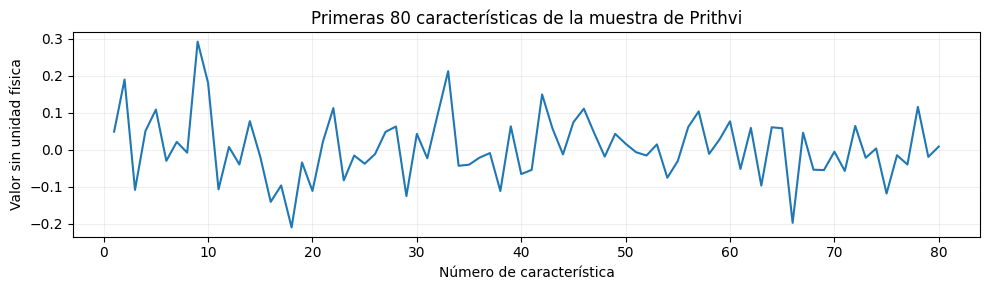

Archivos guardados en: /content/pruebas_ingesta/prithvi


In [ ]:
fechas_contexto = [fecha.isoformat() for fecha in muestra.timestamps]
columnas_features = [f"f_{i:04d}" for i in range(1, vector_prithvi.size + 1)]
tabla_vector = pd.DataFrame([vector_prithvi], columns=columnas_features)
tabla_vector.insert(0, "muestra", str(muestra.chunk_id))
tabla_vector.insert(1, "inicio_contexto", min(fechas_contexto))
tabla_vector.insert(2, "fin_contexto", max(fechas_contexto))
display(tabla_vector.iloc[:, :13])

np.save(DIR_CARACTERISTICAS / "vector_global.npy", vector_prithvi)
np.savez_compressed(
    DIR_CARACTERISTICAS / "caracteristicas.npz",
    vector_global=vector_prithvi,
    vectores_por_fecha_con_contexto=vectores_por_fecha,
    fechas=np.asarray(fechas_contexto),
    cobertura_parches=cobertura_parches,
)
tabla_vector.to_csv(DIR_CARACTERISTICAS / "vector_global.csv", index=False)
metadatos_prithvi = {
    "modelo": PRITHVI_REPO, "revision": PRITHVI_REV,
    "muestra": str(muestra.chunk_id), "fechas_contexto": fechas_contexto,
    "bandas": PRITHVI_BANDS, "resolucion_m": PRITHVI_RES,
    "centro_lat_lon": muestra.location_coords.tolist(),
    "bbox_utm": list(map(float, muestra.bbox)),
    "crs_epsg": int(muestra.bbox.crs.epsg),
    "numero_caracteristicas": int(vector_prithvi.size),
    "resumen": "promedio de tokens sin CLS, ponderado por cobertura >= 0.5",
    "cobertura_valida_por_fecha": muestra.valid.mean(axis=(1, 2)).tolist(),
    "contexto_temporal": "cada resumen usa información de las cuatro fechas",
    "entrenamiento": False,
}
(DIR_CARACTERISTICAS / "metadatos.json").write_text(
    json.dumps(metadatos_prithvi, ensure_ascii=False, indent=2), encoding="utf-8",
)

plt.figure(figsize=(10, 3))
plt.plot(np.arange(1, 81), vector_prithvi[:80])
plt.xlabel("Número de característica")
plt.ylabel("Valor sin unidad física")
plt.title("Primeras 80 características de la muestra de Prithvi")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print("Archivos guardados en:", DIR_CARACTERISTICAS)

## Recibir y visualizar precipitación de ERA5-Land


Se consultará **precipitación total para tres días**. Incluye lluvia y precipitación sólida expresadas como agua equivalente,
con una malla de distribución de 0.1° y resolución nativa aproximada de 9 km.
No tiene el detalle espacial de las imágenes Sentinel-2

**Fechas y acumulación:** en el producto horario original reanalysis-era5-land, la precipitación de las
00:00 UTC corresponde al acumulado de las 24 horas anteriores.
Para representar el 1 de marzo se solicita el 2 de marzo a las 00:00 UTC.
Esta prueba usa esa convención y convierte metros a milímetros multiplicando por 1000.
Los días son UTC, no se están calculando días de calendario en hora de México.
La suma de estos tres días no es un total mensual.

In [ ]:
%pip install -q "cdsapi>=0.7.7,<1" xarray netCDF4

In [ ]:
import os
import json
import math
import hashlib
import shutil
import zipfile
import datetime as dt
from pathlib import Path
from getpass import getpass

import cdsapi
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point

if "AOI_GEOJSON" not in globals():
    raise RuntimeError("Ejecuta antes la celda original que define AOI_GEOJSON.")

ERA5_FECHA_INICIAL = "2026-03-01"  # Primer día que queremos representar.
ERA5_N_DIAS = 3                    # Prueba pequeña: entre 1 y 7 días.
ERA5_DATASET = "reanalysis-era5-land"
DIR_ERA5 = Path("/content/pruebas_ingesta/era5_land")
DIR_ERA5.mkdir(parents=True, exist_ok=True)

if not 1 <= ERA5_N_DIAS <= 7:
    raise ValueError("Esta prueba admite entre 1 y 7 días.")
era5_inicio = dt.date.fromisoformat(ERA5_FECHA_INICIAL)
era5_dias = [era5_inicio + dt.timedelta(days=i) for i in range(ERA5_N_DIAS)]
era5_validez = [dia + dt.timedelta(days=1) for dia in era5_dias]
if max(era5_validez) >= dt.datetime.now(dt.timezone.utc).date() - dt.timedelta(days=7):
    raise ValueError("Elige un periodo histórico terminado hace más de 7 días.")

geometria_era5 = shape(AOI_GEOJSON)
oeste, sur, este, norte = geometria_era5.bounds
if geometria_era5.is_empty or not geometria_era5.is_valid:
    raise ValueError("La geometría del AOI no es válida.")
if (este - oeste) * (norte - sur) > 2:
    raise ValueError("Esta consulta de prueba requiere un AOI pequeño, como el original.")
# Envolvente ampliada a la malla de 0.1°. La máscara posterior usa el polígono real.
ERA5_AREA = [
    round(math.ceil(norte * 10) / 10, 1),
    round(math.floor(oeste * 10) / 10, 1),
    round(math.floor(sur * 10) / 10, 1),
    round(math.ceil(este * 10) / 10, 1),
]

era5_peticiones = []
for anio, mes in sorted({(fecha.year, fecha.month) for fecha in era5_validez}):
    dias_mes = sorted(fecha.day for fecha in era5_validez
                      if (fecha.year, fecha.month) == (anio, mes))
    era5_peticiones.append({
        "variable": ["total_precipitation"],
        "year": [str(anio)], "month": [f"{mes:02d}"],
        "day": [f"{dia:02d}" for dia in dias_mes], "time": ["00:00"],
        "data_format": "netcdf", "download_format": "unarchived",
        "area": ERA5_AREA,
    })

print("Dataset:", ERA5_DATASET)
print("Días de precipitación (UTC):", [dia.isoformat() for dia in era5_dias])
print("Fechas solicitadas a las 00:00 UTC:", [dia.isoformat() for dia in era5_validez])
print("Área solicitada [norte, oeste, sur, este]:", ERA5_AREA)
print("Número de solicitudes pequeñas:", len(era5_peticiones))

Dataset: reanalysis-era5-land
Días de precipitación (UTC): ['2026-03-01', '2026-03-02', '2026-03-03']
Fechas solicitadas a las 00:00 UTC: ['2026-03-02', '2026-03-03', '2026-03-04']
Área solicitada [norte, oeste, sur, este]: [19.7, -102.3, 19.2, -101.6]
Número de solicitudes pequeñas: 1


In [ ]:
def leer_token_cds():
    token = os.environ.get("CDS_API_KEY", "").strip()
    if not token:
        try:
            from google.colab import userdata
            token = (userdata.get("CDS_API_KEY") or "").strip()
        except ImportError:
            pass
        except Exception as error:
            if type(error).__name__ not in {"SecretNotFoundError", "NotebookAccessError"}:
                raise
    if not token:
        token = getpass("CDS_API_KEY (token personal de CDS; entrada oculta): ").strip()
    if not token:
        raise ValueError("Falta el token personal del Climate Data Store.")
    return token


def abrir_respuesta_netcdf(ruta):
    """Lee NetCDF directo o un ZIP con un NetCDF, sin extraer rutas del servidor."""
    ruta = Path(ruta)
    if zipfile.is_zipfile(ruta):
        destino = ruta.parent / (ruta.stem + "_extraido.nc")
        with zipfile.ZipFile(ruta) as archivo:
            miembros = [nombre for nombre in archivo.namelist()
                        if nombre.lower().endswith((".nc", ".nc4", ".netcdf"))]
            if len(miembros) != 1:
                raise ValueError(f"Se esperaba un NetCDF de precipitación; recibidos: {miembros}")
            with archivo.open(miembros[0]) as entrada, destino.open("wb") as salida:
                shutil.copyfileobj(entrada, salida)
        ruta = destino
    with xr.open_dataset(ruta, engine="netcdf4") as dataset:
        return dataset.load()


cliente_cds = None
era5_respuestas = []
for peticion in era5_peticiones:
    huella = hashlib.sha256(json.dumps(peticion, sort_keys=True).encode()).hexdigest()[:12]
    ruta = DIR_ERA5 / f"precipitacion_{huella}.nc"
    if not ruta.is_file():
        if cliente_cds is None:
            cliente_cds = cdsapi.Client(
                url="https://cds.climate.copernicus.eu/api",
                key=leer_token_cds(), quiet=True, debug=False, timeout=60, retry_max=2,
            )
        temporal = ruta.with_suffix(".part")
        print("Consultando CDS. Una petición pequeña también puede esperar en la cola.")
        try:
            cliente_cds.retrieve(ERA5_DATASET, peticion, str(temporal))
            # Comprobar el archivo antes de incorporarlo a la caché.
            abrir_respuesta_netcdf(temporal)
            temporal.replace(ruta)
        except Exception as error:
            temporal.unlink(missing_ok=True)
            raise RuntimeError(
                "No se completó la consulta a CDS. Revisa el token, las condiciones de uso "
                "aceptadas y el estado del servicio. Consulta la excepción original en Colab."
            ) from error
    else:
        print("Se reutiliza la respuesta guardada de esta misma petición:", ruta.name)
    era5_respuestas.append(abrir_respuesta_netcdf(ruta))
del cliente_cds

print("Primera respuesta recibida:")
print(era5_respuestas[0])
print("Variables:", list(era5_respuestas[0].data_vars))
print("Coordenadas:", list(era5_respuestas[0].coords))

Consultando CDS. Una petición pequeña también puede esperar en la cola.


c82a057b513c276016773675f3b1c4a8.nc:   0%|          | 0.00/25.0k [00:00<?, ?B/s]

Primera respuesta recibida:
<xarray.Dataset> Size: 768B
Dimensions:     (valid_time: 3, latitude: 6, longitude: 8)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 24B 2026-03-02 2026-03-03 2026-03-04
  * latitude    (latitude) float64 48B 19.7 19.6 19.5 19.4 19.3 19.2
  * longitude   (longitude) float64 64B -102.3 -102.2 -102.1 ... -101.7 -101.6
    number      int64 8B 0
    expver      (valid_time) <U4 48B '0001' '0001' '0001'
Data variables:
    tp          (valid_time, latitude, longitude) float32 576B 0.001711 ... 0...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-10T02:35 GRIB to CDM+CF via cfgrib-0.9.1...
Variables: ['tp']
Coordenadas: ['number', 'valid_time', 'latitude', 'longitude', 'expver']


In [ ]:
def interpretar_precipitacion_00utc(dataset):
    """Producto horario original: 00 UTC representa el acumulado del día anterior."""
    nombres = [nombre for nombre in ("tp", "total_precipitation") if nombre in dataset.data_vars]
    if len(nombres) != 1:
        raise ValueError(f"No se identifica una única variable de precipitación: {list(dataset.data_vars)}")
    tp = dataset[nombres[0]]
    if "valid_time" in tp.dims:
        tp = tp.rename({"valid_time": "time"})
    necesarias = {"time", "latitude", "longitude"}
    if not necesarias.issubset(tp.dims):
        raise ValueError(f"Dimensiones inesperadas: {tp.dims}")
    for dimension in set(tp.dims) - necesarias:
        if tp.sizes[dimension] != 1:
            raise ValueError(f"Revisa la dimensión adicional {dimension}: {tp.sizes[dimension]}")
        tp = tp.isel({dimension: 0}, drop=True)
    unidades = str(tp.attrs.get("units", "")).strip().lower()
    if unidades not in {"m", "metres", "meters", "m of water equivalent"}:
        raise ValueError(f"Se esperaban metros de agua equivalente, no {unidades!r}.")
    tiempos = pd.DatetimeIndex(tp.time.values)
    if tiempos.has_duplicates or not (tiempos == tiempos.normalize()).all():
        raise ValueError("Esta función requiere una observación por día a las 00:00 UTC.")
    if not np.isfinite(tp.values).any():
        raise ValueError("La respuesta no contiene precipitación válida.")
    if float(tp.min(skipna=True)) < -1e-6:
        raise ValueError("Hay precipitación negativa fuera de la tolerancia de redondeo.")
    # Preservamos NaN y corregimos únicamente pequeños valores negativos numéricos.
    diario = (tp.clip(min=0) * 1000).assign_coords(time=tp.time - np.timedelta64(1, "D"))
    diario = diario.assign_coords(longitude=((diario.longitude + 180) % 360) - 180)
    diario = diario.sortby("longitude").sortby("latitude").sortby("time")
    diario = diario.transpose("time", "latitude", "longitude")
    diario.name = "precipitacion_diaria_mm"
    diario.attrs = {
        "units": "mm",
        "descripcion": "Precipitación total de 24 h del día etiquetado, de 00 a 00 UTC",
        "fuente": ERA5_DATASET,
    }
    return diario


era5_diario = xr.concat(
    [interpretar_precipitacion_00utc(respuesta) for respuesta in era5_respuestas],
    dim="time", join="exact",
).sortby("time")
fechas_recibidas = pd.DatetimeIndex(era5_diario.time.values)
fechas_esperadas = pd.DatetimeIndex(pd.to_datetime(era5_dias))
if fechas_recibidas.has_duplicates or not fechas_recibidas.equals(fechas_esperadas):
    raise ValueError("Las fechas recibidas no coinciden con los días solicitados.")

lon_malla, lat_malla = np.meshgrid(era5_diario.longitude.values, era5_diario.latitude.values)
centros_dentro = np.array([
    geometria_era5.covers(Point(float(lon), float(lat)))
    for lon, lat in zip(lon_malla.ravel(), lat_malla.ravel())
]).reshape(lon_malla.shape)
if not centros_dentro.any():
    raise ValueError("No hay centros de celda dentro del AOI; revisa su tamaño frente a la malla de 0.1°.")
mascara_aoi_era5 = xr.DataArray(
    centros_dentro, dims=("latitude", "longitude"),
    coords={"latitude": era5_diario.latitude, "longitude": era5_diario.longitude},
)
lluvia_aoi = era5_diario.where(mascara_aoi_era5)
conteos_validos = lluvia_aoi.count(dim=("latitude", "longitude"))
if bool((conteos_validos == 0).any()):
    raise ValueError("Algún día no tiene datos de precipitación válidos dentro del AOI.")

# Promedio de celdas cuyos centros caen dentro del AOI, ponderado por coseno de latitud.
# Es un resumen regional para esta prueba, no un cálculo exacto por parcela o por área de intersección.
pesos_latitud = np.cos(np.deg2rad(lluvia_aoi.latitude))
media_lluvia = lluvia_aoi.weighted(pesos_latitud).mean(("latitude", "longitude"), skipna=True)
resumen_lluvia = pd.DataFrame({
    "fecha_utc": fechas_recibidas.strftime("%Y-%m-%d"),
    "precipitacion_media_aoi_mm": media_lluvia.values,
    "celdas_con_dato": conteos_validos.values.astype(int),
})
display(resumen_lluvia)
print("Forma del dato climático (días, latitudes, longitudes):", lluvia_aoi.shape)
print("Unidad original:", era5_respuestas[0][
    next(nombre for nombre in ("tp", "total_precipitation") if nombre in era5_respuestas[0])
].attrs.get("units"))
print("Unidad de la tabla:", lluvia_aoi.attrs["units"])

,fecha_utc,precipitacion_media_aoi_mm,celdas_con_dato
0,2026-03-01,0.899777,24
1,2026-03-02,0.192834,24
2,2026-03-03,0.187512,24


Forma del dato climático (días, latitudes, longitudes): (3, 6, 8)
Unidad original: m
Unidad de la tabla: mm


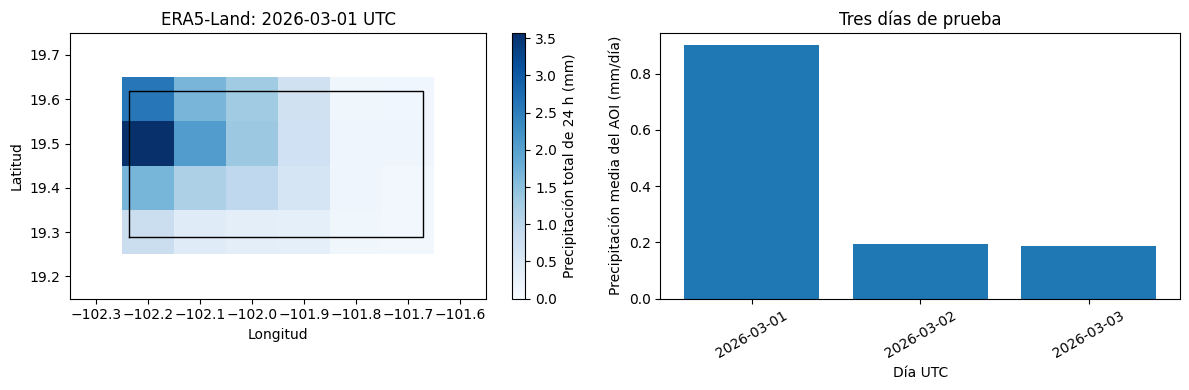

Archivos guardados en: /content/pruebas_ingesta/era5_land


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mapa = lluvia_aoi.isel(time=0)
malla = axes[0].pcolormesh(
    mapa.longitude, mapa.latitude, mapa.values,
    shading="nearest", cmap="Blues", vmin=0, vmax=max(float(mapa.max()), 0.01),
)
for poligono in getattr(geometria_era5, "geoms", [geometria_era5]):
    lon_borde, lat_borde = poligono.exterior.xy
    axes[0].plot(lon_borde, lat_borde, color="black", linewidth=1)
fig.colorbar(malla, ax=axes[0], label="Precipitación total de 24 h (mm)")
axes[0].set_title(f"ERA5-Land: {resumen_lluvia.fecha_utc.iloc[0]} UTC")
axes[0].set_xlabel("Longitud")
axes[0].set_ylabel("Latitud")
axes[1].bar(resumen_lluvia.fecha_utc, resumen_lluvia.precipitacion_media_aoi_mm)
axes[1].set_ylabel("Precipitación media del AOI (mm/día)")
axes[1].set_xlabel("Día UTC")
axes[1].set_title("Tres días de prueba" if ERA5_N_DIAS == 3 else "Días de prueba")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

resumen_lluvia.to_csv(DIR_ERA5 / "resumen_diario_aoi.csv", index=False)
tabla_celdas = lluvia_aoi.to_dataframe().reset_index().dropna(subset=["precipitacion_diaria_mm"])
tabla_celdas.to_csv(DIR_ERA5 / "precipitacion_por_celda.csv", index=False)
lluvia_aoi.to_netcdf(DIR_ERA5 / "precipitacion_diaria_mm.nc", engine="netcdf4")
metadatos_era5 = {
    "dataset": ERA5_DATASET, "aoi_geojson": AOI_GEOJSON,
    "dias_representados_utc": [dia.isoformat() for dia in era5_dias],
    "peticiones": era5_peticiones,
    "convencion": "00 UTC del día siguiente contiene el acumulado de las 24 h del día etiquetado",
    "unidad_original": "m", "unidad_salida": "mm",
    "malla_grados": 0.1, "resolucion_nativa_aproximada_km": 9,
    "resumen_espacial": "centros dentro del AOI; promedio ponderado por coseno de latitud",
    "tipo": "reanálisis histórico; no pronóstico ni medición de estación",
    "documentacion": "https://confluence.ecmwf.int/spaces/CKB/pages/140385202/ERA5-Land+data+documentation",
}
(DIR_ERA5 / "metadatos.json").write_text(
    json.dumps(metadatos_era5, ensure_ascii=False, indent=2), encoding="utf-8",
)
print("Archivos guardados en:", DIR_ERA5)